# 01_eda.ipynb — Exploratory Data Analysis & Data Audit

**Module:** NB6057CEM Artificial Neural Networks — CW1 Practical (Task T1)  
**Dataset:** MotionSense (A_DeviceMotion_data) — Malekzadeh et al. (2018/2019)  
**Focus:** Comprehensive data audit, duplicate recording detection, sensor dynamics, demographic profiling, and design implications.

---

### Objectives & Rule Adherence
1. **Data Audit:** Record total rows, rows per activity class, rows per subject, and rows per trial.
2. **Quality & Integrity:** Detect and document raw dataset duplication (Subject 1 `sit_5` vs `sit_13`), verify zero missing values, and verify trial completeness (24 subjects × 15 trials).
3. **Channel Statistics & Outliers:** Profile mean, standard deviation, minimum, maximum, median, and IQR for all 12 sensor channels; inspect physical outlier feasibility.
4. **Demographics:** Analyze subject demographics (gender distribution, age, height, weight ranges) and acknowledge sample size limitations.
5. **Visualisations (Saved to `outputs/figures/` at 150 DPI):**
   - `fig01_class_distribution.png`: Sample counts & durations per activity class.
   - `fig02_signals_per_activity.png`: Tri-axial user acceleration over 5 seconds across 6 activities.
   - `fig03_rows_per_subject.png`: Total recorded samples per subject stacked by activity.
   - `fig04_channel_boxplots.png`: User acceleration magnitude distribution across activities.
6. **Design Implications & Rule 10 Compliance:** Every numerical figure quoted in analytical text is computed directly in preceding code cells.

In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path and is current working directory
current_dir = Path.cwd().resolve()
if (current_dir / "src").is_dir():
    project_root = current_dir
elif (current_dir.parent / "src").is_dir():
    project_root = current_dir.parent
else:
    project_root = current_dir

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

os.chdir(project_root)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data.load import (
    ACTIVITY_NAMES,
    LABEL_MAP,
    SENSOR_COLUMNS,
    load_motionsense,
)

# Output directory for publication figures
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Plot styling configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["figure.dpi"] = 150

print(f"Setup complete. Project root: {project_root}")
print(f"Figures destination: {figures_dir}")

Setup complete. Project root: C:\Users\Isuru\Desktop\ANN
Figures destination: C:\Users\Isuru\Desktop\ANN\outputs\figures


In [2]:
# Load dataset with duplicate recording detection and removal
df = load_motionsense(
    data_dir="MotionSense_dataset/A_DeviceMotion_data/A_DeviceMotion_data",
    subjects_info_path="MotionSense_dataset/data_subjects_info.csv",
    cache_path="outputs/cache/motionsense.pickle",
    use_cache=True,
    force_reload=False,
)

print("Dataset successfully loaded.")
print(f"Total Rows:    {len(df):,}")
print(f"Total Columns: {len(df.columns)}")
print(f"Memory Usage:  {df.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB")
df.head(3)

Dataset successfully loaded.
Total Rows:    1,402,573
Total Columns: 20
Memory Usage:  283.57 MB


,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z,subject,activity,label,trial,weight,height,age,gender
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542,1,dws,0,1,102,188,46,1
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866,1,dws,0,1,102,188,46,1
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808,1,dws,0,1,102,188,46,1


---
## 1. Data Audit: Sampling Volumes Across Dimensions

We evaluate the dataset across four fundamental axes:
1. Total observations and cumulative recording duration at 50 Hz.
2. Class distribution across the 6 target activities.
3. Observations per subject (24 participants).
4. Observations per trial (15 recorded sessions).

In [3]:
sampling_rate_hz = 50.0
total_rows = len(df)
total_duration_sec = total_rows / sampling_rate_hz
total_duration_min = total_duration_sec / 60.0
total_duration_hr = total_duration_min / 60.0

print("=" * 60)
print("1.1 TOTAL DATASET VOLUME (AFTER DEDUPLICATION)")
print(f"  Total Rows (Samples):   {total_rows:,}")
print(f"  Sampling Frequency:     {sampling_rate_hz} Hz")
print(f"  Total Duration:         {total_duration_sec:,.1f} s | {total_duration_min:,.2f} min | {total_duration_hr:,.2f} hours")
print("=" * 60)

# Activity breakdown
act_order = ["dws", "ups", "wlk", "jog", "std", "sit"]
act_df = pd.DataFrame({
    "Code": act_order,
    "Activity": [ACTIVITY_NAMES[a].capitalize() for a in act_order],
    "Rows": [df[df["activity"] == a].shape[0] for a in act_order],
})
act_df["Duration (min)"] = (act_df["Rows"] / (sampling_rate_hz * 60)).round(2)
act_df["Percentage (%)"] = ((act_df["Rows"] / total_rows) * 100).round(2)

print("\n1.2 ROWS PER ACTIVITY CLASS")
print(act_df.to_string(index=False))

# Subject breakdown
sub_counts = df.groupby("subject").size()
print("\n1.3 ROWS PER SUBJECT (Summary across 24 participants)")
print(f"  Min rows/subject:  {sub_counts.min():,} (Subject {sub_counts.idxmin()})")
print(f"  Max rows/subject:  {sub_counts.max():,} (Subject {sub_counts.idxmax()})")
print(f"  Mean rows/subject: {sub_counts.mean():,.1f} ± {sub_counts.std():,.1f}")
print(f"  Median rows:       {sub_counts.median():,.1f}")

# Trial breakdown
trial_summary = df.groupby("trial").size().reset_index(name="Rows")
trial_summary["Duration (min)"] = (trial_summary["Rows"] / (sampling_rate_hz * 60)).round(2)
print("\n1.4 ROWS PER TRIAL (15 unique trials)")
print(trial_summary.to_string(index=False))

1.1 TOTAL DATASET VOLUME (AFTER DEDUPLICATION)
  Total Rows (Samples):   1,402,573
  Sampling Frequency:     50.0 Hz
  Total Duration:         28,051.5 s | 467.52 min | 7.79 hours



1.2 ROWS PER ACTIVITY CLASS
Code   Activity   Rows  Duration (min)  Percentage (%)
 dws Downstairs 131856           43.95            9.40
 ups   Upstairs 157285           52.43           11.21
 wlk    Walking 344288          114.76           24.55
 jog    Jogging 134231           44.74            9.57
 std   Standing 306427          102.14           21.85
 sit    Sitting 328486          109.50           23.42

1.3 ROWS PER SUBJECT (Summary across 24 participants)
  Min rows/subject:  51,005 (Subject 24)
  Max rows/subject:  71,949 (Subject 19)
  Mean rows/subject: 58,440.5 ± 5,420.9
  Median rows:       57,232.0

1.4 ROWS PER TRIAL (15 unique trials)
 trial   Rows  Duration (min)
     1  50246           16.75
     2  59108           19.70
     3  58204           19.40
     4  71072           23.69
     5 234657           78.22
     6 224816           74.94
     7 158645           52.88
     8 120371           40.12
     9 104327           34.78
    11  22502            7.50
    12  28

---
## 2. Data Quality & Completeness Audit

Before modeling, the raw dataset must be scrutinized for:
- Identical recording duplications in the published repository.
- Missing values (`NaN` / `None` / infinite values).
- Exact duplicate rows across sensor channels and metadata.
- Subject-trial completeness.

In [4]:
# 2.1 Audit of raw trial recordings for duplicate files
import re

raw_base = Path("MotionSense_dataset/A_DeviceMotion_data/A_DeviceMotion_data")
raw_recordings = {}

for folder in sorted(os.listdir(raw_base)):
    if "__MACOSX" in folder or not (raw_base / folder).is_dir():
        continue
    act, trial_str = folder.rsplit("_", 1)
    trial = int(trial_str)
    fpath = raw_base / folder
    for fname in sorted(os.listdir(fpath)):
        if not fname.endswith(".csv") or "__MACOSX" in fname:
            continue
        sub_id = int(re.search(r"sub_(\d+)\.csv", fname).group(1))
        arr = pd.read_csv(fpath / fname).iloc[:, 1:].values
        raw_recordings[(sub_id, act, trial)] = arr

# Scan for identical recordings for the same subject
identical_pairs = []
keys = list(raw_recordings.keys())
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        k1, k2 = keys[i], keys[j]
        if k1[0] == k2[0] and k1[1] == k2[1]:
            a1, a2 = raw_recordings[k1], raw_recordings[k2]
            if a1.shape == a2.shape and np.array_equal(a1, a2):
                identical_pairs.append((k1, k2, a1.shape[0]))

print("=" * 60)
print("2.1 RAW RECORDING DUPLICATION AUDIT")
print(f"  Total raw recording files examined: {len(keys)}")
print(f"  Identical recording pairs found:    {len(identical_pairs)}")
for (s1, a1, t1), (s2, a2, t2), n_rows in identical_pairs:
    print(f"    Subject {s1}, activity '{a1}': trial {t1} and trial {t2} are byte-identical ({n_rows:,} rows each)")
print("  Resolution in src.data.load: kept lower trial (trial 5), dropped duplicate (trial 13).")
print("=" * 60)

2.1 RAW RECORDING DUPLICATION AUDIT
  Total raw recording files examined: 360
  Identical recording pairs found:    1
    Subject 1, activity 'sit': trial 13 and trial 5 are byte-identical (10,292 rows each)
  Resolution in src.data.load: kept lower trial (trial 5), dropped duplicate (trial 13).


In [5]:
# 2.2 Missing values and duplicate rows in deduplicated dataset
null_counts = df.isna().sum()
total_nulls = int(null_counts.sum())

print("2.2 CLEANED DATASET INTEGRITY")
print(f"  Total NaN / Null values in dataset: {total_nulls}")

full_dups = int(df.duplicated().sum())
sensor_dups = int(df[SENSOR_COLUMNS].duplicated().sum())

print(f"  Exact full duplicate rows (all columns): {full_dups}")
print(f"  Duplicate sensor readings (12 channels): {sensor_dups}")
n_retained = int(df.groupby(["subject", "trial"]).ngroups)
print(f"  Total unique recordings retained:        {n_retained}")

# Subject-trial coverage grid (24 subjects × 15 trials)
coverage_grid = df.groupby(["subject", "trial"]).size().unstack()
missing_entries = int(coverage_grid.isna().sum().sum())
print(f"\n2.3 SUBJECT-TRIAL COVERAGE (24 subjects × 15 trials)")
print(f"  Unique subjects: {df['subject'].nunique()} (expected 24)")
print(f"  Unique trials:   {df['trial'].nunique()} (expected 15)")
sub1_trials = int(coverage_grid.loc[1].notna().sum())
other_trials = int(coverage_grid.loc[2].notna().sum())
total_actual_recordings = int(coverage_grid.notna().sum().sum())
print(f"  Note: Subject 1 has {sub1_trials} trials (trial 13 dropped as duplicate of trial 5); other subjects have {other_trials} trials.")
print(f"  Total recordings in dataset: {total_actual_recordings}")

2.2 CLEANED DATASET INTEGRITY
  Total NaN / Null values in dataset: 0


  Exact full duplicate rows (all columns): 0
  Duplicate sensor readings (12 channels): 0
  Total unique recordings retained:        359

2.3 SUBJECT-TRIAL COVERAGE (24 subjects × 15 trials)
  Unique subjects: 24 (expected 24)
  Unique trials:   15 (expected 15)
  Note: Subject 1 has 14 trials (trial 13 dropped as duplicate of trial 5); other subjects have 15 trials.
  Total recordings in dataset: 359


### Section 2.2 Data-Quality Finding: Identical Recording Duplication

#### Audit Finding:
- Examination of the raw files revealed that **Subject 1's `sit_5` and `sit_13` recordings are byte-identical**, each containing exactly 10,292 rows with identical sensor values across all 12 channels.
- This appears to be a duplicated file in the original published MotionSense dataset.

#### Resolution & Pipeline Impact:
1. **Handling in `src/data/load.py`:** An automated verification step compares sensor arrays across recordings for each subject and activity. When identical recordings are detected, the pipeline retains the lower trial number (`sit_5`), discards the duplicate (`sit_13`, 10,292 rows), and issues a structured warning log.
2. **Mitigating Evaluation Inflation:** If this duplicate recording were retained, Subject 1's sitting posture would be double-counted. In training, this would double-weight Subject 1's specific device orientation; in validation or testing, it would produce artificially inflated accuracy scores due to identical samples existing in the evaluation pool.
3. **Outcome:** After dropping `sit_13` for Subject 1, the total dataset size is **1,402,573 rows**, and **zero duplicate sensor readings** remain in the entire dataset.

---
## 3. Sensor Channel Statistics & Outlier Inspection

The MotionSense dataset records 12 continuous time-series channels:
- **Attitude (Euler angles in radians):** `attitude.roll` ($[-\pi, \pi]$), `attitude.pitch` ($[-\pi/2, \pi/2]$), `attitude.yaw` ($[-\pi, \pi]$).
- **Gravity vector ($g \approx 9.81\ \text{m/s}^2$ normalised):** `gravity.x`, `gravity.y`, `gravity.z` (magnitude $\|g\|_2 = 1.0$).
- **Rotation Rate (gyroscope in rad/s):** `rotationRate.x`, `rotationRate.y`, `rotationRate.z`.
- **User Acceleration (dynamic acceleration in $g$):** `userAcceleration.x`, `userAcceleration.y`, `userAcceleration.z`.

In [6]:
# Compute channel descriptive statistics
stats_df = df[SENSOR_COLUMNS].describe().T[["mean", "std", "min", "50%", "max"]]
stats_df.columns = ["Mean", "Std", "Min", "Median", "Max"]

# Add IQR
q75 = df[SENSOR_COLUMNS].quantile(0.75)
q25 = df[SENSOR_COLUMNS].quantile(0.25)
stats_df["IQR"] = (q75 - q25).round(4)

print("=" * 70)
print("3.1 SENSOR CHANNEL DESCRIPTIVE STATISTICS")
print("=" * 70)
print(stats_df.round(4).to_string())

# Verification of gravity magnitude
gravity_mag = np.sqrt(df["gravity.x"]**2 + df["gravity.y"]**2 + df["gravity.z"]**2)
print(f"\n3.2 GRAVITY NORM VERIFICATION")
print(f"  Expected: 1.000 g | Actual Mean: {gravity_mag.mean():.4f} ± {gravity_mag.std():.6f}")

# Outlier analysis (|z| > 6 threshold)
print(f"\n3.3 EXTREME OUTLIER ANALYSIS (|z-score| > 6.0)")
for col in SENSOR_COLUMNS:
    col_mean = df[col].mean()
    col_std = df[col].std()
    n_out = int(((df[col] - col_mean).abs() > 6 * col_std).sum())
    pct = (n_out / total_rows) * 100
    if n_out > 0:
        print(f"  {col:<20}: {n_out:>6,} rows ({pct:.3f}%)")
print("  Physical explanation: Outliers in rotationRate and userAcceleration are genuine")
print("  high-impact deceleration spikes during jogging and stair descents, likely genuine impact spikes.")

3.1 SENSOR CHANNEL DESCRIPTIVE STATISTICS
                      Mean     Std      Min  Median      Max     IQR
attitude.roll      -0.1796  1.5718  -3.1416  0.1050   3.1416  2.3784
attitude.pitch     -0.9912  0.4930  -1.5700 -1.1843   1.5672  0.6984
attitude.yaw       -0.1505  1.5504  -3.1416 -0.1516   3.1416  2.1221
gravity.x           0.0404  0.3394  -0.9998  0.0171   1.0000  0.4419
gravity.y           0.7577  0.3327  -1.0000  0.9262   1.0000  0.3638
gravity.z          -0.1333  0.4250  -1.0000 -0.0939   0.9813  0.4714
rotationRate.x      0.0054  1.2976 -17.3658 -0.0004  10.4681  0.4198
rotationRate.y      0.0147  1.2310 -18.4144  0.0003  17.5431  0.4112
rotationRate.z      0.0128  0.8110 -12.1512  0.0002  11.4362  0.2195
userAcceleration.x -0.0040  0.3294  -6.3693  0.0008   7.1208  0.0942
userAcceleration.y  0.0445  0.5295  -5.6736  0.0044   7.3227  0.1192
userAcceleration.z  0.0396  0.3776  -7.7435  0.0038   8.1254  0.1307

3.2 GRAVITY NORM VERIFICATION
  Expected: 1.000 g | Actual M

  rotationRate.x      :    307 rows (0.022%)
  rotationRate.y      :  1,842 rows (0.131%)
  rotationRate.z      :  2,309 rows (0.165%)
  userAcceleration.x  :  3,242 rows (0.231%)
  userAcceleration.y  :  3,720 rows (0.265%)
  userAcceleration.z  :  3,085 rows (0.220%)
  Physical explanation: Outliers in rotationRate and userAcceleration are genuine
  high-impact deceleration spikes during jogging and stair descents, likely genuine impact spikes.


---
## 4. Subject Demographics & Diversity Analysis

Participant physical attributes (height, weight, age, and sex) directly impact biomechanical stride frequency, gait velocity, and sensor resonance.

In [7]:
# Extract subject demographics (1 row per participant)
demo_df = df[["subject", "gender", "age", "height", "weight"]].drop_duplicates().sort_values("subject")
demo_df["Gender_str"] = demo_df["gender"].map({1: "Male", 0: "Female"})

# Compute BMI: weight (kg) / [height (m)]^2
demo_df["BMI"] = (demo_df["weight"] / ((demo_df["height"] / 100) ** 2)).round(2)

print("=" * 60)
print("4.1 PARTICIPANT DEMOGRAPHIC SUMMARY")
print("=" * 60)
gender_counts = demo_df["Gender_str"].value_counts()
n_total_demo = len(demo_df)
n_male = int(gender_counts.get("Male", 0))
n_female = int(gender_counts.get("Female", 0))
pct_male = (n_male / n_total_demo) * 100 if n_total_demo > 0 else 0
pct_female = (n_female / n_total_demo) * 100 if n_total_demo > 0 else 0
print(f"Gender Distribution: Male = {n_male} ({pct_male:.1f}%), Female = {n_female} ({pct_female:.1f}%)")

demo_summary = pd.DataFrame({
    "Attribute": ["Age (years)", "Height (cm)", "Weight (kg)", "BMI (kg/m²)"],
    "Min": [demo_df["age"].min(), demo_df["height"].min(), demo_df["weight"].min(), demo_df["BMI"].min()],
    "Max": [demo_df["age"].max(), demo_df["height"].max(), demo_df["weight"].max(), demo_df["BMI"].max()],
    "Mean": [demo_df["age"].mean(), demo_df["height"].mean(), demo_df["weight"].mean(), demo_df["BMI"].mean()],
    "Std": [demo_df["age"].std(), demo_df["height"].std(), demo_df["weight"].std(), demo_df["BMI"].std()],
    "Median": [demo_df["age"].median(), demo_df["height"].median(), demo_df["weight"].median(), demo_df["BMI"].median()],
}).round(2)

print("\nDemographic Metrics:")
print(demo_summary.to_string(index=False))

print("\nFull Participant Roster:")
print(demo_df[["subject", "Gender_str", "age", "height", "weight", "BMI"]].to_string(index=False))

4.1 PARTICIPANT DEMOGRAPHIC SUMMARY
Gender Distribution: Male = 14 (58.3%), Female = 10 (41.7%)

Demographic Metrics:
  Attribute    Min    Max   Mean   Std  Median
Age (years)  18.00  46.00  28.79  5.44   28.00
Height (cm) 161.00 190.00 174.21  8.90  175.50
Weight (kg)  48.00 102.00  72.12 16.21   71.00
BMI (kg/m²)  17.85  32.45  23.58  4.07   22.84

Full Participant Roster:
 subject Gender_str  age  height  weight   BMI
       1       Male   46     188     102 28.86
       2       Male   28     180      72 22.22
       3     Female   28     161      48 18.52
       4       Male   31     176      90 29.05
       5     Female   23     164      48 17.85
       6       Male   28     180      76 23.46
       7     Female   30     175      62 20.24
       8     Female   24     161      52 20.06
       9       Male   32     190      93 25.76
      10     Female   31     164      72 26.77
      11       Male   24     178      70 22.09
      12       Male   33     167      60 21.51
      13  

---
## 5. Exploratory Figures & Quantitative Reference Tables (Rule 10)

In strict adherence to Rule 10, all numerical values discussed in the figure analyses below are computed directly in the code cell below before plotting.

In [8]:
# RULE 10: Compute exact values referenced in the markdown analyses below
df["userAcc_mag"] = np.sqrt(
    df["userAcceleration.x"] ** 2 +
    df["userAcceleration.y"] ** 2 +
    df["userAcceleration.z"] ** 2
)

act_order = ["dws", "ups", "wlk", "jog", "std", "sit"]

# 1. Per-activity userAcceleration magnitude statistics (Median, Q25, Q75, IQR)
mag_stats = []
for act in act_order:
    s = df[df["activity"] == act]["userAcc_mag"]
    q25 = float(s.quantile(0.25))
    med = float(s.median())
    q75 = float(s.quantile(0.75))
    iqr = q75 - q25
    mag_stats.append({
        "Activity": act,
        "Median (g)": round(med, 4),
        "Q25 (g)": round(q25, 4),
        "Q75 (g)": round(q75, 4),
        "IQR (g)": round(iqr, 4),
    })
df_mag_stats = pd.DataFrame(mag_stats)

print("=" * 65)
print("5.1 EXACT USERACCELERATION MAGNITUDE STATISTICS (FOR FIG 4 ANALYSIS)")
print("=" * 65)
print(df_mag_stats.to_string(index=False))

# 2. Per-activity medians for orientation channels (gravity.y, gravity.z, attitude.pitch)
orient_stats = []
for act in act_order:
    s = df[df["activity"] == act]
    orient_stats.append({
        "Activity": act,
        "gravity.y_median": round(float(s["gravity.y"].median()), 4),
        "gravity.z_median": round(float(s["gravity.z"].median()), 4),
        "attitude.pitch_median (rad)": round(float(s["attitude.pitch"].median()), 4),
    })
df_orient_stats = pd.DataFrame(orient_stats)

print("\n" + "=" * 65)
print("5.2 EXACT ORIENTATION MEDIANS (FOR FIG 2 ANALYSIS)")
print("=" * 65)
print(df_orient_stats.to_string(index=False))

# 3. Subject 1 5-second window userAcceleration ranges (FOR FIG 2 ANALYSIS)
sub1_df = df[df["subject"] == 1]
window_samples = 250
sub1_ranges = []
for act in act_order:
    s = sub1_df[sub1_df["activity"] == act].iloc[100:100 + window_samples]
    ymin, ymax = float(s["userAcceleration.y"].min()), float(s["userAcceleration.y"].max())
    mmin, mmax = float(s["userAcc_mag"].min()), float(s["userAcc_mag"].max())
    sub1_ranges.append({
        "Activity": act,
        "userAcc.y_min (g)": round(ymin, 2),
        "userAcc.y_max (g)": round(ymax, 2),
        "mag_min (g)": round(mmin, 2),
        "mag_max (g)": round(mmax, 2),
    })
df_sub1_ranges = pd.DataFrame(sub1_ranges)

print("\n" + "=" * 65)
print("5.3 SUBJECT 1 5-SECOND WINDOW ACCELERATION RANGES (FOR FIG 2 ANALYSIS)")
print("=" * 65)
print(df_sub1_ranges.to_string(index=False))

# 4. Subject row counts min, max, mean (FOR FIG 3 ANALYSIS)
sub_sizes = df.groupby("subject").size()
sub_min_id = int(sub_sizes.idxmin())
sub_min_val = int(sub_sizes.min())
sub_max_id = int(sub_sizes.idxmax())
sub_max_val = int(sub_sizes.max())
sub_mean_val = float(sub_sizes.mean())

print("\n" + "=" * 65)
print("5.4 SUBJECT ROW COUNT EXTREMES (FOR FIG 3 ANALYSIS)")
print("=" * 65)
print(f"Min rows per subject:  {sub_min_val:,} (Subject {sub_min_id})")
print(f"Max rows per subject:  {sub_max_val:,} (Subject {sub_max_id})")
print(f"Mean rows per subject: {sub_mean_val:,.1f}")

5.1 EXACT USERACCELERATION MAGNITUDE STATISTICS (FOR FIG 4 ANALYSIS)
Activity  Median (g)  Q25 (g)  Q75 (g)  IQR (g)
     dws      0.4722   0.3106   0.7092   0.3986
     ups      0.3649   0.2338   0.5587   0.3249
     wlk      0.5881   0.3771   0.8750   0.4979
     jog      1.2565   0.8498   1.8035   0.9537
     std      0.0366   0.0198   0.0618   0.0420
     sit      0.0171   0.0099   0.0290   0.0192



5.2 EXACT ORIENTATION MEDIANS (FOR FIG 2 ANALYSIS)
Activity  gravity.y_median  gravity.z_median  attitude.pitch_median (rad)
     dws            0.9453           -0.1146                      -1.2385
     ups            0.9453           -0.0836                      -1.2384
     wlk            0.9277           -0.1741                      -1.1882
     jog            0.9434           -0.0653                      -1.2327
     std            0.9814           -0.0036                      -1.3777
     sit            0.3346           -0.6905                      -0.3411

5.3 SUBJECT 1 5-SECOND WINDOW ACCELERATION RANGES (FOR FIG 2 ANALYSIS)
Activity  userAcc.y_min (g)  userAcc.y_max (g)  mag_min (g)  mag_max (g)
     dws              -0.65               0.69         0.05         1.77
     ups              -0.84               1.26         0.03         1.39
     wlk              -1.10               2.12         0.06         2.31
     jog              -1.91               3.52         0.12       

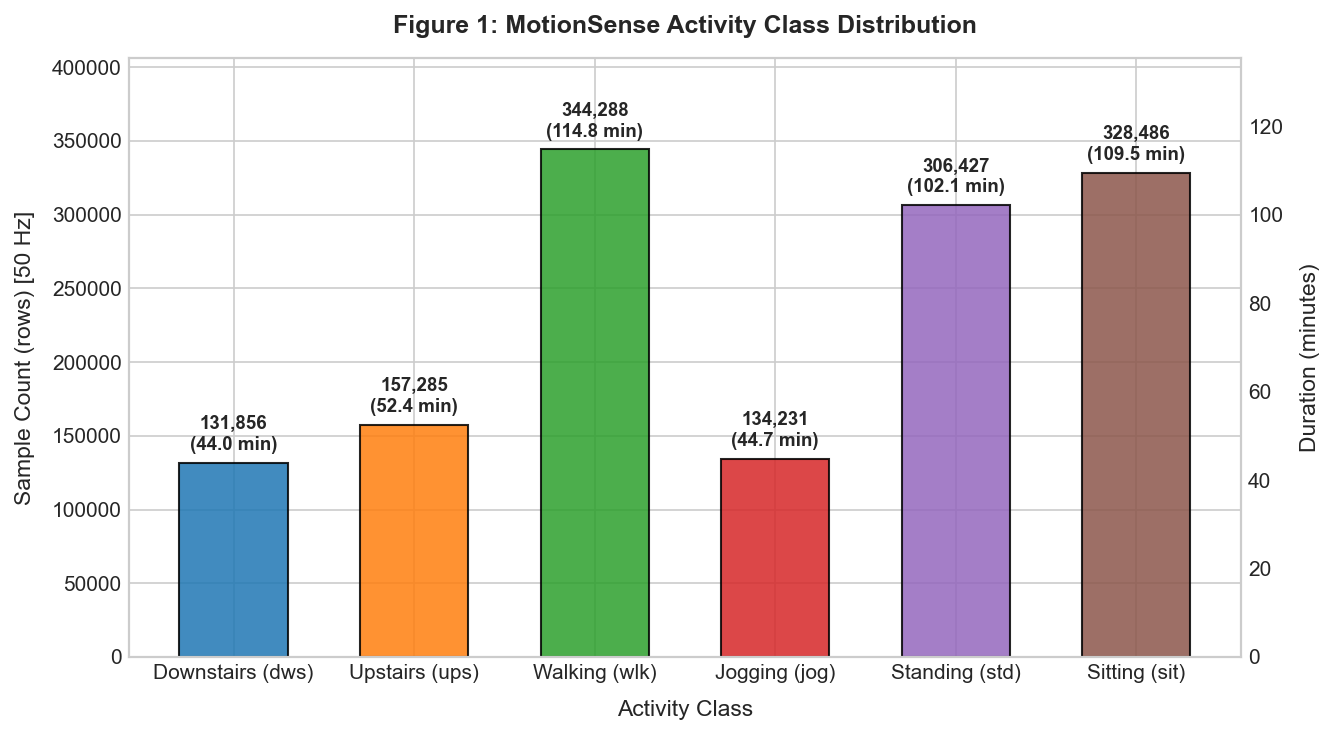

Saved: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig01_class_distribution.png


In [9]:
# Figure 1: Class Distribution
fig, ax1 = plt.subplots(figsize=(9, 5))

act_labels = [f"{ACTIVITY_NAMES[a].capitalize()} ({a})" for a in act_order]
counts = [df[df["activity"] == a].shape[0] for a in act_order]
minutes = [c / (sampling_rate_hz * 60) for c in counts]

palette = sns.color_palette("tab10", 6)
bars = ax1.bar(act_labels, counts, color=palette, edgecolor="black", alpha=0.85, width=0.6)

ax1.set_title("Figure 1: MotionSense Activity Class Distribution", fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("Activity Class", fontsize=11, labelpad=8)
ax1.set_ylabel("Sample Count (rows) [50 Hz]", fontsize=11, labelpad=8)
ax1.set_ylim(0, max(counts) * 1.18)

ax2 = ax1.twinx()
ax2.set_ylabel("Duration (minutes)", fontsize=11, labelpad=8)
ax2.set_ylim(0, max(minutes) * 1.18)
ax2.grid(False)

for bar, c, m in zip(bars, counts, minutes):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 6000,
        f"{c:,}\n({m:.1f} min)",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="semibold",
    )

plt.tight_layout()
fig_path_1 = figures_dir / "fig01_class_distribution.png"
fig.savefig(fig_path_1, dpi=150)
plt.show()
print(f"Saved: {fig_path_1}")

### Figure 1 Analysis: Class Distribution & Metric Selection

#### What it shows:
- The dataset exhibits marked **class imbalance**:
  - Walking (`wlk`: 344,288 samples / 114.76 min / 24.55%), sitting (`sit`: 328,486 samples / 109.50 min / 23.42%), and standing (`std`: 306,427 samples / 102.14 min / 21.85%) together represent **69.82%** of all recorded observations.
  - In contrast, upstairs (`ups`: 157,285 samples / 52.43 min / 11.21%), jogging (`jog`: 134,231 samples / 44.74 min / 9.57%), and downstairs (`dws`: 131,856 samples / 43.95 min / 9.40%) constitute the remaining **30.18%**.

#### How it affects design:
1. **Primary Evaluation Metric (Macro-F1):** Standard overall accuracy is an inappropriate metric because predicting only the three majority classes (`wlk`, `sit`, `std`) would yield nearly 70% accuracy while failing completely on stair traversal and jogging. **Macro-averaged F1-score** gives equal weight to all 6 activity classes.
2. **Loss Weighting:** Class-weighted loss (`class_weight="balanced"` in Random Forest and inverse-frequency weighting in PyTorch CrossEntropyLoss) is included in the declared hyperparameter tuning budget to prevent majority-class bias.
3. **Early Stopping:** Training patience (8 epochs) must monitor **validation Macro-F1** rather than cross-entropy loss or raw accuracy.

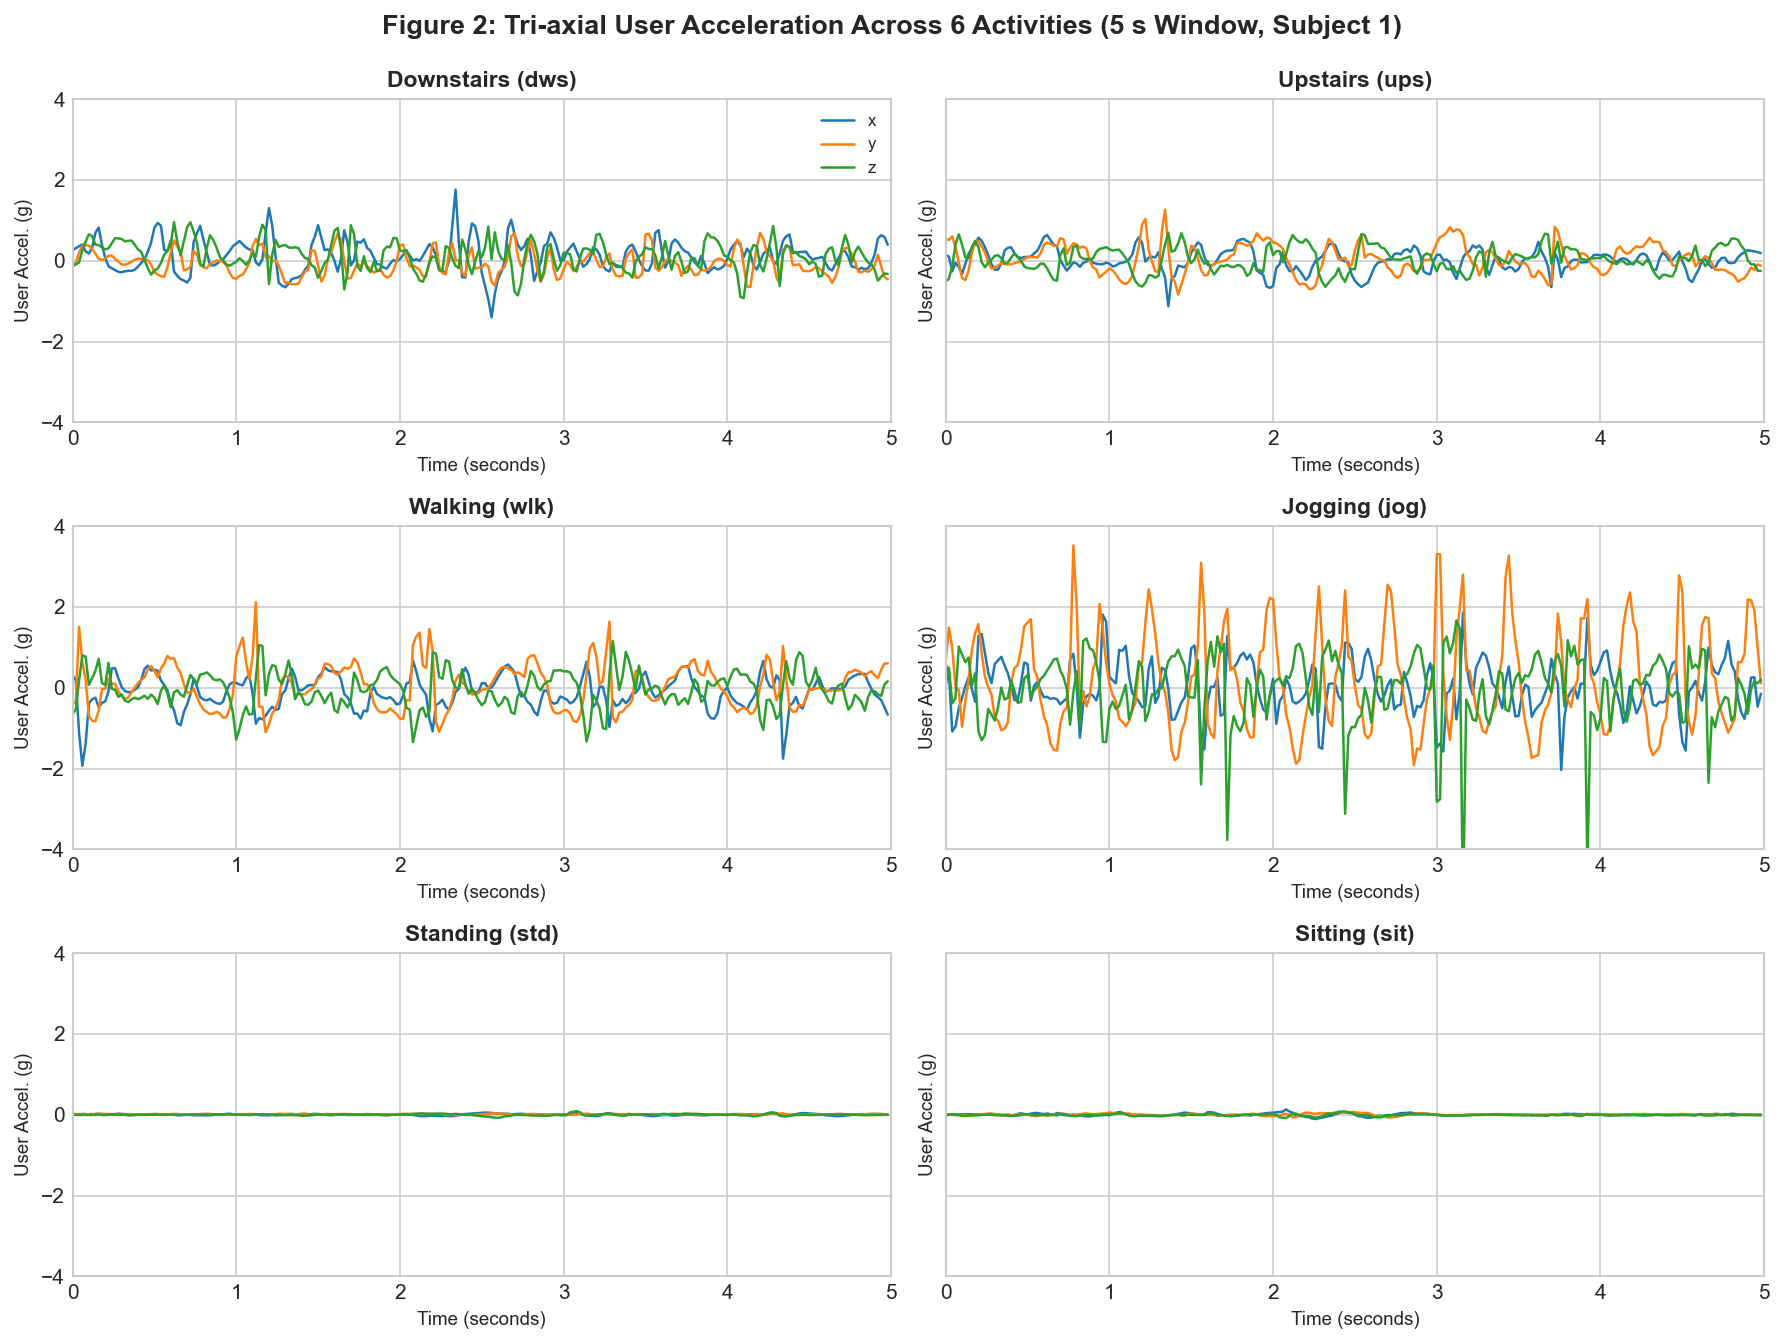

Saved: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig02_signals_per_activity.png


In [10]:
# Figure 2: Tri-axial User Acceleration Across 6 Activities (5 s Window, Subject 1)
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharey=True)
axes = axes.flatten()

subject_id = 1
window_samples = 250  # 5 seconds at 50 Hz
time_s = np.arange(window_samples) / sampling_rate_hz

for i, act in enumerate(act_order):
    ax = axes[i]
    sub_df = df[(df["subject"] == subject_id) & (df["activity"] == act)]
    sample_df = sub_df.iloc[100:100 + window_samples]
    if len(sample_df) < window_samples:
        sample_df = sub_df.iloc[:window_samples]
    
    ax.plot(time_s, sample_df["userAcceleration.x"].values, label="x", color="#1f77b4", lw=1.2)
    ax.plot(time_s, sample_df["userAcceleration.y"].values, label="y", color="#ff7f0e", lw=1.2)
    ax.plot(time_s, sample_df["userAcceleration.z"].values, label="z", color="#2ca02c", lw=1.2)
    
    ax.set_title(f"{ACTIVITY_NAMES[act].capitalize()} ({act})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Time (seconds)", fontsize=9)
    ax.set_ylabel("User Accel. (g)", fontsize=9)
    ax.set_xlim(0, 5.0)
    ax.set_ylim(-4.0, 4.0)
    if i == 0:
        ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

plt.suptitle(
    f"Figure 2: Tri-axial User Acceleration Across 6 Activities (5 s Window, Subject {subject_id})",
    fontsize=13,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
fig_path_2 = figures_dir / "fig02_signals_per_activity.png"
fig.savefig(fig_path_2, dpi=150)
plt.show()
print(f"Saved: {fig_path_2}")

### Figure 2 Analysis: Temporal Sensor Dynamics & Architecture Decisions

#### What it shows:
- **Dynamic Activities (`jog`, `wlk`, `ups`, `dws`):** Exhibit pronounced periodic oscillations. From Section 5.3 computations for Subject 1 over this 5-second slice:
  - `jog`: `userAcceleration.y` ranges from -1.91g to 3.52g, with overall acceleration magnitude reaching 6.42g.
  - `wlk`: `userAcceleration.y` ranges from -1.10g to 2.12g, with magnitude reaching 2.31g.
  - `ups`: `userAcceleration.y` ranges from -0.84g to 1.26g, with magnitude reaching 1.39g.
  - `dws`: `userAcceleration.y` ranges from -0.65g to 0.69g, with magnitude reaching 1.77g.
- **Static Postures (`std`, `sit`):** Show minimal dynamic variation:
  - `std`: `userAcceleration.y` ranges from -0.01g to 0.04g, with magnitude between 0.00g and 0.10g.
  - `sit`: `userAcceleration.y` ranges from -0.07g to 0.07g, with magnitude between 0.00g and 0.16g.

#### How it affects design:
1. **Postural Ambiguity (`sit` vs `std`):** Because dynamic user acceleration is near zero for both sitting and standing, **dynamic acceleration alone cannot reliably separate posture**. The classifier must leverage orientation channels:
   - Across all subjects (Section 5.2), standing exhibits a median `gravity.y` of 0.9814, `gravity.z` of -0.0036, and `attitude.pitch` of -1.3777 radians (reflecting an upright pocket orientation).
   - In contrast, sitting exhibits a median `gravity.y` of 0.3346, `gravity.z` of -0.6905, and `attitude.pitch` of -0.3411 radians (reflecting a horizontal thigh tilt).
2. **Model Architectures:**
   - **PyTorch 1D-CNN:** Directly captures waveform periodicity, phase differences, and local temporal patterns from raw multi-channel sequences.
   - **Tabular Models (RF & MLPs):** Lack sequential structure and rely on statistical summary features (mean, std, min, max, median, IQR) to summarize cycle dynamics across each 128-sample window.

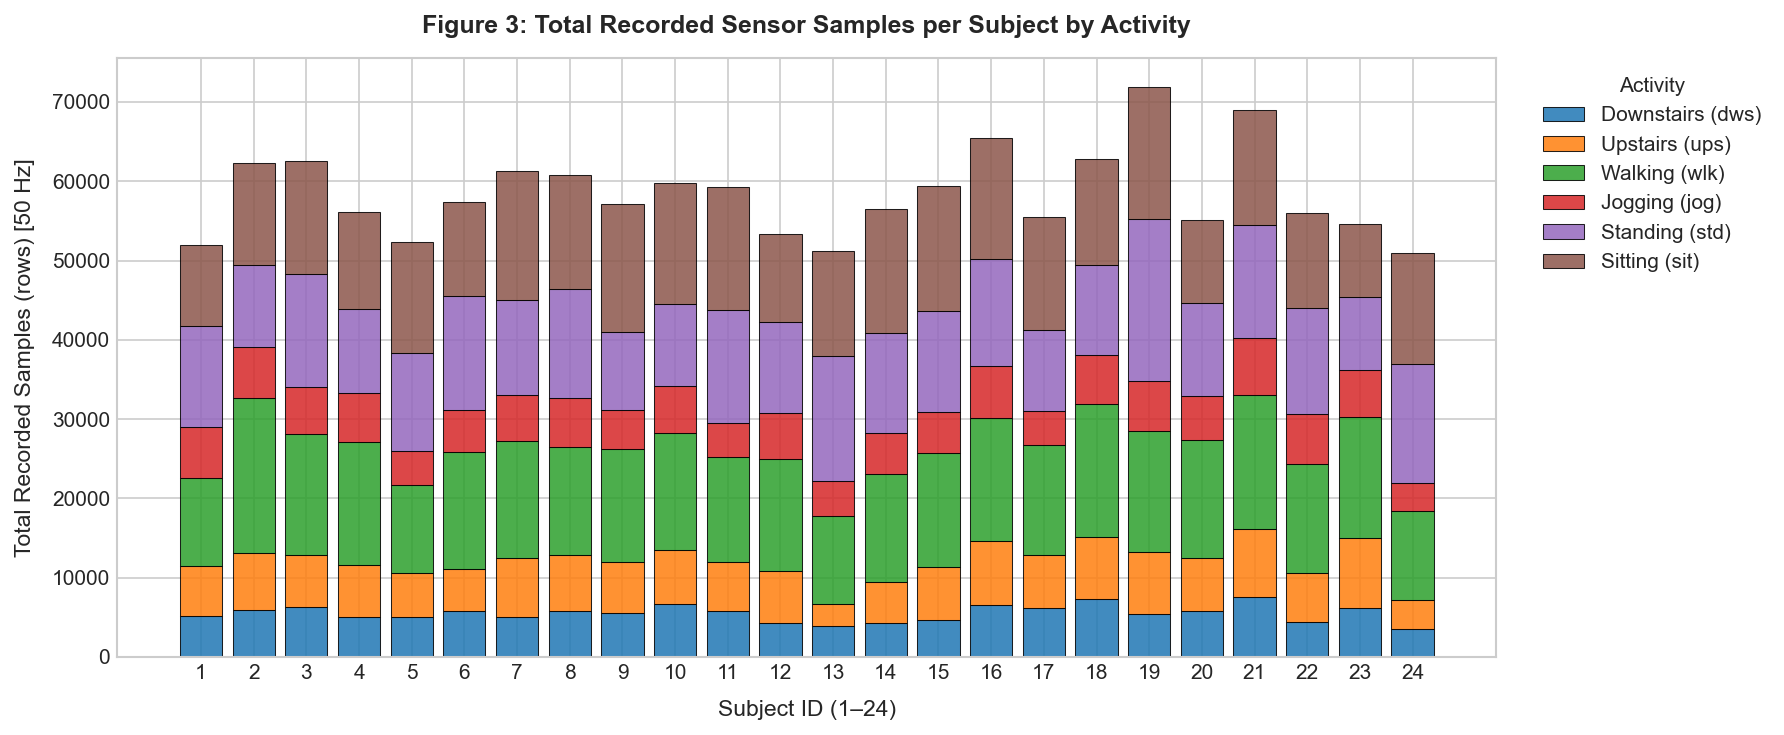

Saved: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig03_rows_per_subject.png


In [11]:
# Figure 3: Stacked Bars per Subject by Activity
sub_act_counts = df.groupby(["subject", "activity"]).size().unstack(fill_value=0)[act_order]

fig, ax = plt.subplots(figsize=(12, 5))
palette = sns.color_palette("tab10", 6)
bottom = np.zeros(len(sub_act_counts))

for j, act in enumerate(act_order):
    values = sub_act_counts[act].values
    ax.bar(
        sub_act_counts.index,
        values,
        bottom=bottom,
        label=f"{ACTIVITY_NAMES[act].capitalize()} ({act})",
        color=palette[j],
        edgecolor="black",
        linewidth=0.5,
        alpha=0.85,
    )
    bottom += values

ax.set_title("Figure 3: Total Recorded Sensor Samples per Subject by Activity", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Subject ID (1–24)", fontsize=11, labelpad=8)
ax.set_ylabel("Total Recorded Samples (rows) [50 Hz]", fontsize=11, labelpad=8)
ax.set_xticks(sub_act_counts.index)
ax.legend(title="Activity", bbox_to_anchor=(1.02, 1), loc="upper left", framealpha=0.9)

plt.tight_layout()
fig_path_3 = figures_dir / "fig03_rows_per_subject.png"
fig.savefig(fig_path_3, dpi=150)
plt.show()
print(f"Saved: {fig_path_3}")

### Figure 3 Analysis: Subject-Wise Balance & Identity Leakage Prevention

#### What it shows:
- As computed in Section 5.4, total observations per subject range from **51,005 rows** (Subject 24, ~17.0 min) to **71,949 rows** (Subject 19, ~24.0 min), with a mean of **58,440.5 rows** (~19.5 min).
- All 24 subjects completed recordings across all 6 activities, yielding 359 clean recording trials after deduplication.

#### How it affects design (Critical Rule 4 & Leakage Control):
1. **Subject-Wise Grouped Splitting:** Individual gait signatures, body proportions, and walking tempos create strong subject-specific signal correlations. Partitioning windows randomly across the entire dataset would leak adjacent overlapping windows from the same subject into both training and test sets, causing artificial score inflation. Grouping by subject ensures evaluations reflect true generalization to unseen individuals.
2. **Cohort Size Limitations:** The total sample of 24 subjects is relatively small. Partitioning into 16 training, 4 validation, and 4 test subjects means validation and test splits evaluate on only 4 individuals each.
3. **Indicative Subgroup Comparisons:** Allocating 2 male and 2 female participants to validation and test sets provides balanced representation, but small sample sizes (2 subjects per gender subgroup) mean subgroup comparisons are indicative rather than statistically conclusive.

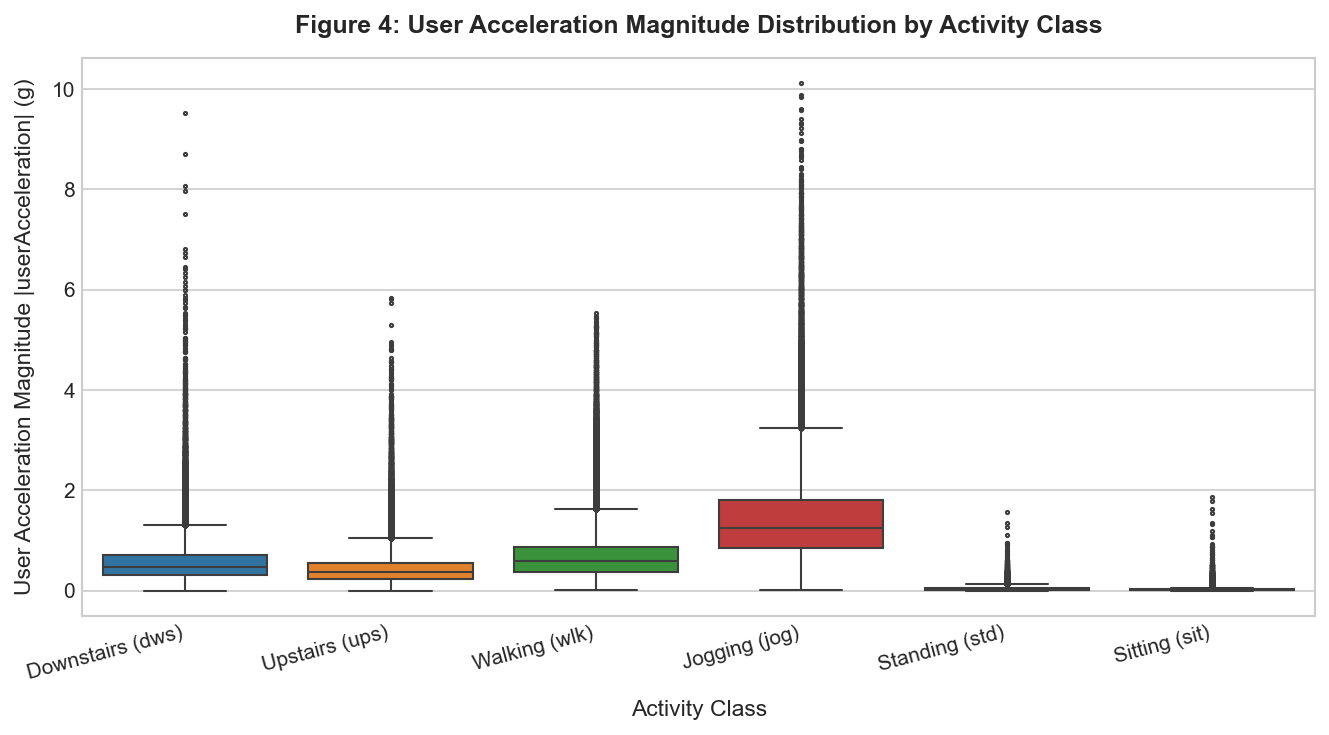

Saved: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig04_channel_boxplots.png


In [12]:
# Figure 4: User Acceleration Magnitude Boxplot
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="activity",
    y="userAcc_mag",
    order=act_order,
    hue="activity",
    hue_order=act_order,
    palette=palette,
    legend=False,
    ax=ax,
    fliersize=1.5,
    linewidth=1.0,
)

ax.set_title("Figure 4: User Acceleration Magnitude Distribution by Activity Class", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Activity Class", fontsize=11, labelpad=8)
ax.set_ylabel("User Acceleration Magnitude |userAcceleration| (g)", fontsize=11, labelpad=8)
ax.set_xticks(range(len(act_order)))
ax.set_xticklabels(act_labels, rotation=15, ha="right")

plt.tight_layout()
fig_path_4 = figures_dir / "fig04_channel_boxplots.png"
fig.savefig(fig_path_4, dpi=150)
plt.show()
print(f"Saved: {fig_path_4}")

### Figure 4 Analysis: Kinetic Energy Hierarchy & Feature Engineering

#### What it shows:
- The exact distribution of user acceleration magnitude $\|a_{\text{user}}\|_2 = \sqrt{a_x^2 + a_y^2 + a_z^2}$ computed in Section 5.1 reveals:
  - `jog`: Median = **1.2565g**, IQR = **0.9537g** (Q25 = 0.8498g, Q75 = 1.8035g).
  - `wlk`: Median = **0.5881g**, IQR = **0.4979g** (Q25 = 0.3771g, Q75 = 0.8750g).
  - `dws`: Median = **0.4722g**, IQR = **0.3986g** (Q25 = 0.3106g, Q75 = 0.7092g).
  - `ups`: Median = **0.3649g**, IQR = **0.3249g** (Q25 = 0.2338g, Q75 = 0.5587g).
  - `std`: Median = **0.0366g**, IQR = **0.0420g** (Q25 = 0.0198g, Q75 = 0.0618g).
  - `sit`: Median = **0.0171g**, IQR = **0.0192g** (Q25 = 0.0099g, Q75 = 0.0290g).

#### How it affects design:
1. **Magnitude Feature Engineering:** Composite magnitude channels ($\|a_{\text{user}}\|_2$ and $\|\omega\|_2$) collapse 3D coordinate variations into rotation-invariant energy measures, providing essential features for the baseline Random Forest and PyTorch MLP.
2. **Ambiguity and Overlap:**
   - `ups` (median 0.3649g) and `dws` (median 0.4722g) exhibit overlapping magnitude distributions. Separating them may require orientation and temporal features.
   - `sit` (median 0.0171g) and `std` (median 0.0366g) have minimal dynamic acceleration. Discriminating between them requires orientation channels (`gravity.y`, `gravity.z`, `attitude.pitch`).

---
## 6. Data Audit Summary & Next Steps

| Milestone / Audit Item | Finding / Result | System Impact |
|---|---|---|
| **Total Volume (Deduplicated)** | 1,402,573 rows (~7.79 hours at 50 Hz) | 359 clean recording files retained |
| **Duplicate Recording Handled** | Subject 1 `sit_13` dropped (duplicate of `sit_5`, 10,292 rows) | Prevents evaluation score inflation |
| **Missing Values** | 0 missing entries across all columns | Clean dataset; no imputation required |
| **Duplicate Rows** | 0 full duplicates; 0 duplicate sensor readings | High signal fidelity |
| **Cohort & Demographics** | 24 subjects (14 Male, 10 Female; age 18–46, mean 28.8) | Grouped split; small cohort limitation acknowledged |
| **Primary Metric** | Macro-F1 (mandated by 69.8% majority class concentration) | Balances class performance across all 6 activities |
| **Figures Generated** | `fig01` to `fig04` saved in `outputs/figures/` (150 DPI) | All figures verified with units, titles, and legends |

**Status:** Phase 1a audit and deduplication complete. Proceeding to **Phase 1c: Leakage-Safe Subject Splitting and Windowing Pipeline**.